# Práctica 0 - Aprendizaje Avanzado

### Izan Cuesta Corbí

##### Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

## 1. Preprocesamiento de Datos

### 1.1 Exploración Inicial y Tipos de Datos

In [ ]:
# Cargar datos
df = pd.read_csv('./healthcare-dataset-stroke-data.csv')

# Dimensiones
print("*" * 40)
print(f"Shape: {df.shape}")
print("*" * 40)
# Tipos de datos
print(df.dtypes)
print("*" * 40)
# Primeras filas
print(df.head())
print("*" * 40)
# Resumen rápido
print(df.info())
print("*" * 40)
# Valores faltantes
print(df.isnull().sum())

****************************************
Shape: (5110, 12)
****************************************
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object
****************************************
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Pr

### 1.2 Manejo de Valores Faltantes

In [ ]:
# Estrategia 1: Eliminar filas con cualquier faltante
df_clean = df.dropna()
# Eliminar filas donde el género sea 'Other'
df_clean = df_clean[df_clean['gender'] != 'Other']
# Eliminar columna 'id' (solo introduce ruido)
df_clean = df_clean.drop(columns=['id'])

df_clean.to_csv('versions/01_dataset_clean.csv', index=False)

Dado que los valores faltantes de BMI representan menos del 5% del dataset (201), se decidió eliminar esas filas para trabajar únicamente con datos reales y evitar el sesgo introducido por la imputación. 

Además, he detectado que en la categoría 'gender' había una fila asignada a 'Other' en vez de utilizar 'Male' o 'Female', por tanto, para evitar problemas futuros con la codificación de esa variable he decidido eliminarla.

También, he eliminado la columna 'id' que funcionaba como identificador de cada uno de los pacientes debido a que no aportaba información relevante para el entrenamiento del modelo y era puro ruido.

### 1.3 Tratamiento de Outliers

In [ ]:
def detectar_outliers(columna):    
    # Detección por IQR
    Q1 = df_clean[columna].quantile(0.25)
    Q3 = df_clean[columna].quantile(0.75)
    IQR = Q3 - Q1

    outliers = (df_clean[columna] < Q1 - 1.5*IQR) | (df_clean[columna] > Q3 + 1.5*IQR)
    print(f"Outliers detectados: {outliers.sum()}")

    # Visualización
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Box plot
    axes[0].boxplot(df_clean[columna])
    axes[0].set_title(f'Box Plot - f{columna}')
    axes[0].set_ylabel('Valor')

    # Scatter plot
    axes[1].scatter(range(len(df_clean)), df_clean[columna].sort_values())
    axes[1].set_title('Distribución de valores')
    axes[1].set_ylabel(f'{columna} (ordenado)')

    plt.tight_layout()
    plt.savefig(f'./images/outliers_detection_{columna}.png', dpi=400, bbox_inches='tight')
    plt.show()
    plt.close()

##### Age

Outliers detectados: 0


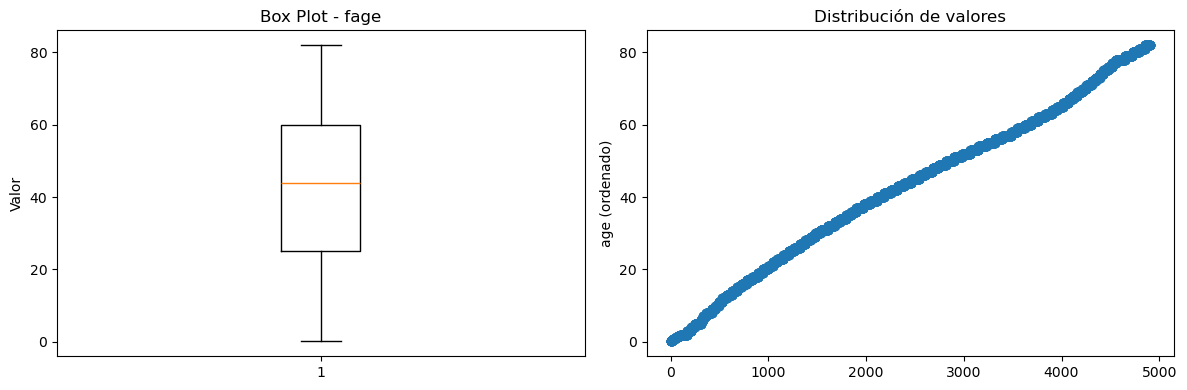

In [ ]:
detectar_outliers('age')

##### BMI

Outliers detectados: 110


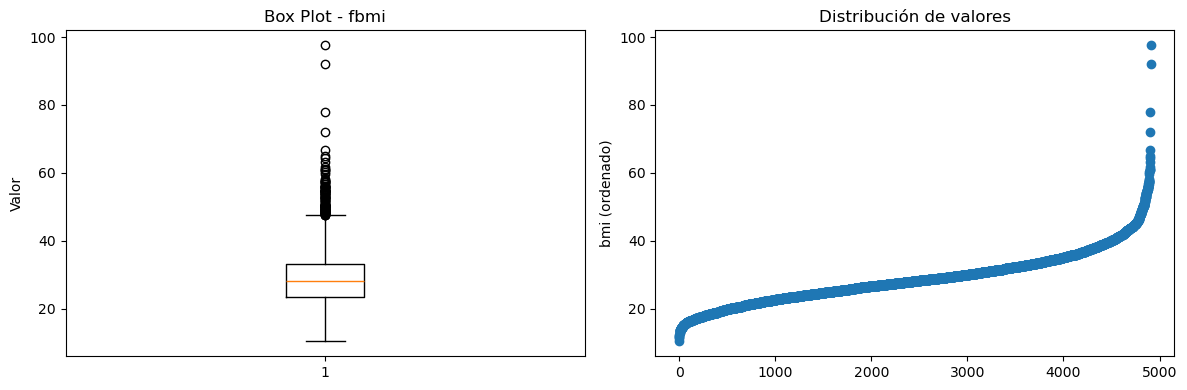

In [ ]:
detectar_outliers('bmi')

El BMI es una medida estándar que utiliza la estatura y el peso para clasificar a las personas. Mientras la mayoría de la población se concentra entre 20 y 40, existen outliers extremos con valores de hasta 97.6. Estos representan casos extremos de obesidad que, pese a que pueden ser reales, pueden llegar a distorsionar el aprendizaje del modelo, ya que un valor de BMI mayor de 40 ya está representando la obesidad mórbida, correspondiendo al último caso dentro de su rango de clasificación (el más grave). Por tanto, todo lo que esté por encima ya será tremendamente nocivo para la salud y no habrá una grandísma diferencia entre los propios casos de obesidad mórbida.

Para ajustar los outliers, he aplicado una transformación logarítmica que comprime los valores extremos, permitiendo que el modelo considere estos casos como "riesgo alto" sin que un valor de 97 tenga un peso desproporcionado frente a un valor de 45.

##### Average Glucose Level

Outliers detectados: 569


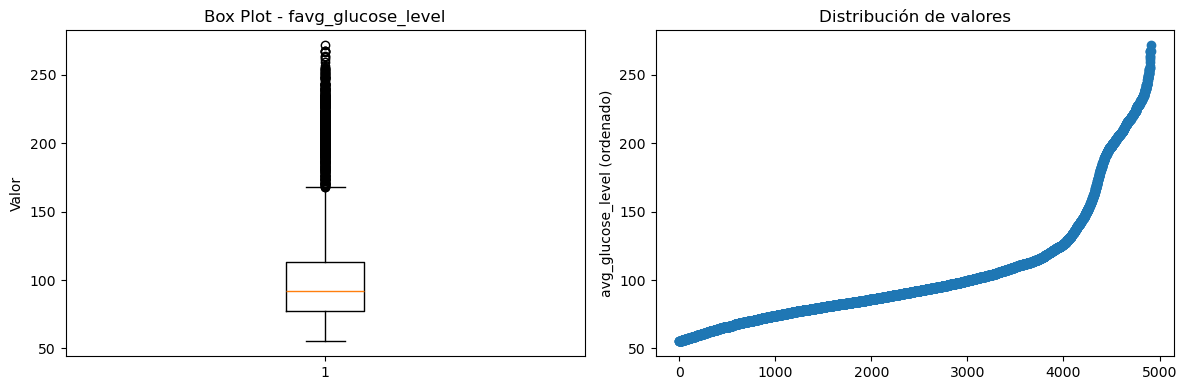

In [ ]:
detectar_outliers('avg_glucose_level')

El nivel de glucosa representa la concentración media de azúcar en sangre. Es un indicador directo del metabolismo y la diabetes, donde muchos pacientes tienen valores normales entre 80 y 100, pero se detecta un grupo significativo de outliers con valores entre 200 y 271. Desde el punto de vista médico, los valores de glucosa por encima de 200 mg/dL indican una diabetes severa en el paciente. 

A diferencia del BMI, en los outliers de glucosa una diferencia entre valores altos si que indica un peligro mucho mayor, por lo que si se transformasen los valores estaríamos ocultando al modelo la gravedad del estado del paciente. En este caso, para esta variable categórica no realizaremos ninguna transformación, ya que estaríamos perdiendo datos importantes al hacer la predicción.

##### Transformación aplicada al BMI

In [ ]:
df_outliers = df_clean.copy()
# Aplicar Transformación Logarítmica
df_outliers['bmi_log'] = np.log1p(df_outliers['bmi'])
df_outliers = df_outliers.drop(columns=['bmi'])
df_outliers.to_csv('versions/02_dataset_outliers.csv', index=False)

### 1.4 Transformación de Variables

Dado que posteriormente tengo que splitar el dataset en los diferentes conjuntos de datos de entrenamiento y test, no voy a realizar todavía la transformación de las variables numéricas y trabajaré en el resto de apartados de análisis con el dataset sin transformar. Sin embargo, ya puedo decidir que técnica voy a utilizar según las características de mi dataset: utilizaré el Standard Scaler correspondiente a la técnica de Estandarización (Z-score).

Una de las razones por las que me he decantado por este método ha sido la transformación que he realizado en el paso anterior a la variable 'bmi'. Al aplicarle una transformación logarítmica hemos convertido la distribución del BMI en una distribución normal, lo que potencia el uso de Standard Scaler, que es la técnica por defecto para modelos lineales.
Respecto a las otras dos variables, la estandarización respetará los outliers de 'avg_glucose_level' para que se mantenga esa diferencia importante en los resultados y en 'age' no ocurrirá ningún problema ya que es una variable estándar.

### 1.5 Codificación de Variables Categóricas

##### Análisis de 'smoking_status'

In [ ]:
# Calcular el riesgo por categoría de fumador
risk_smoking = df_outliers.groupby('smoking_status')['stroke'].mean() * 100
risk_smoking_sorted = risk_smoking.sort_values(ascending=False)

print("Riesgo de Ictus por hábito de fumar (%):")
print(risk_smoking_sorted)

Riesgo de Ictus por hábito de fumar (%):
smoking_status
formerly smoked    6.818182
smokes             5.291723
never smoked       4.535637
Unknown            1.955496
Name: stroke, dtype: float64


##### Codificación

In [ ]:
df_encoded = df_outliers.copy()

# Label Encoding
le = LabelEncoder()
df_encoded['gender'] = le.fit_transform(df_encoded['gender'])
df_encoded['ever_married'] = le.fit_transform(df_encoded['ever_married'])
df_encoded['Residence_type'] = le.fit_transform(df_encoded['Residence_type'])

# One-Hot Encoding
# get_dummies crea las columnas nuevas y elimina las originales automáticamente
df_encoded = pd.get_dummies(df_encoded, columns=['work_type', 'smoking_status'], drop_first=True)
# Al hacer drop_first=True elimina una de las clases ya que para n clases se necesitan n-1 variables dummy (evita redundancia)
# Variables no creadas -> work_type: Govt_job / smoking_status: Unknown
# Estas variables están implícitas (no tienen su columna propia en el dataframe) y se han convertido en la categoría de referencia
# cuando todas las variables dan 0 (false) significa que estas son True

print(df_encoded.tail())
df_encoded.to_csv('versions/03_dataset_encoded.csv', index=False)

      gender   age  hypertension  heart_disease  ever_married  Residence_type  \
5104       0  13.0             0              0             0               0   
5106       0  81.0             0              0             1               1   
5107       0  35.0             0              0             1               0   
5108       1  51.0             0              0             1               0   
5109       0  44.0             0              0             1               1   

      avg_glucose_level  stroke   bmi_log  work_type_Never_worked  \
5104             103.08       0  2.975530                   False   
5106             125.20       0  3.713572                   False   
5107              82.99       0  3.453157                   False   
5108             166.29       0  3.280911                   False   
5109              85.28       0  3.303217                   False   

      work_type_Private  work_type_Self-employed  work_type_children  \
5104              False   

En las variables binarias ('ever_married', 'residence_type', 'gender'), utilizamos Label Encoding, conviertiendo Casado(1)/No casado(0), Urbana(1)/Rural(0) y Hombre(1)/Mujer(0). Para las variables binarias, el uso de Label Encoding y One-Hot Encoding es práctimente el mismo ya que no se le está pasando como parámetro un orden, sino la presencia o no de la variable, por lo que he decidido usarla para probar más de una técnica. 

*La variable 'gender' no era binaria sino que tenía tres respuestas ('male', 'female', 'other'), pero en el caso de 'other' solo existía una fila que la contase, por tanto en el apartado 1.2 decicí eliminarla para hacer más sencilla la codificación.

En el caso de 'smoking_status', inicialmente había considerado usar Label Encoding bajo la hipótesis médica de que fumar aumenta el riesgo progresivamente, siendo el orden lógico: 'never smoked' < 'formerly smoked' < 'smokes'. Sin embargo, al analizar los datos, se observa que la categoría 'formerly smoked' presentaba mayor riesgo de ictus en esta muestra que 'smokes' (posiblemente debido a la edad o condiciones preexistentes de quienes dejan de fumar), siendo los resultados:
- formerly smoked: 7.9% de riesgo.
- smokes: 5.3% de riesgo.
- never smoked: 4.8% de riesgo.
- Unknown: 3.0% de riesgo. 

Además, la presencia de la categoría 'Unknown' no permite establecer un orden lineal claro y tendríamos que no darle ningún valor o inventárnoslo. Por ello, he optado por One-Hot Encoding para tratar cada categoría de forma independiente sin introducir sesgos de orden incorrectos y sin asumir ningún orden.

En el caso de work_type, directamente no existe ningún orden intrínseco, por lo que son categorías nominales y también usaremos One-Hot Encoding.


## 2. Análisis Exploratorio de Datos (EDA)

### 2.1 Estadística Descriptiva

In [ ]:
# Resumen rápido
print(df_encoded.describe())

            gender          age  hypertension  heart_disease  ever_married  \
count  4908.000000  4908.000000   4908.000000    4908.000000   4908.000000   
mean      0.409739    42.868810      0.091891       0.049511      0.652812   
std       0.491836    22.556128      0.288901       0.216954      0.476125   
min       0.000000     0.080000      0.000000       0.000000      0.000000   
25%       0.000000    25.000000      0.000000       0.000000      0.000000   
50%       0.000000    44.000000      0.000000       0.000000      1.000000   
75%       1.000000    60.000000      0.000000       0.000000      1.000000   
max       1.000000    82.000000      1.000000       1.000000      1.000000   

       Residence_type  avg_glucose_level       stroke      bmi_log  
count     4908.000000        4908.000000  4908.000000  4908.000000  
mean         0.507335         105.297402     0.042584     3.364879  
std          0.499997          44.425550     0.201937     0.255595  
min          0.000000

### 2.2 Distribuciones Univariadas

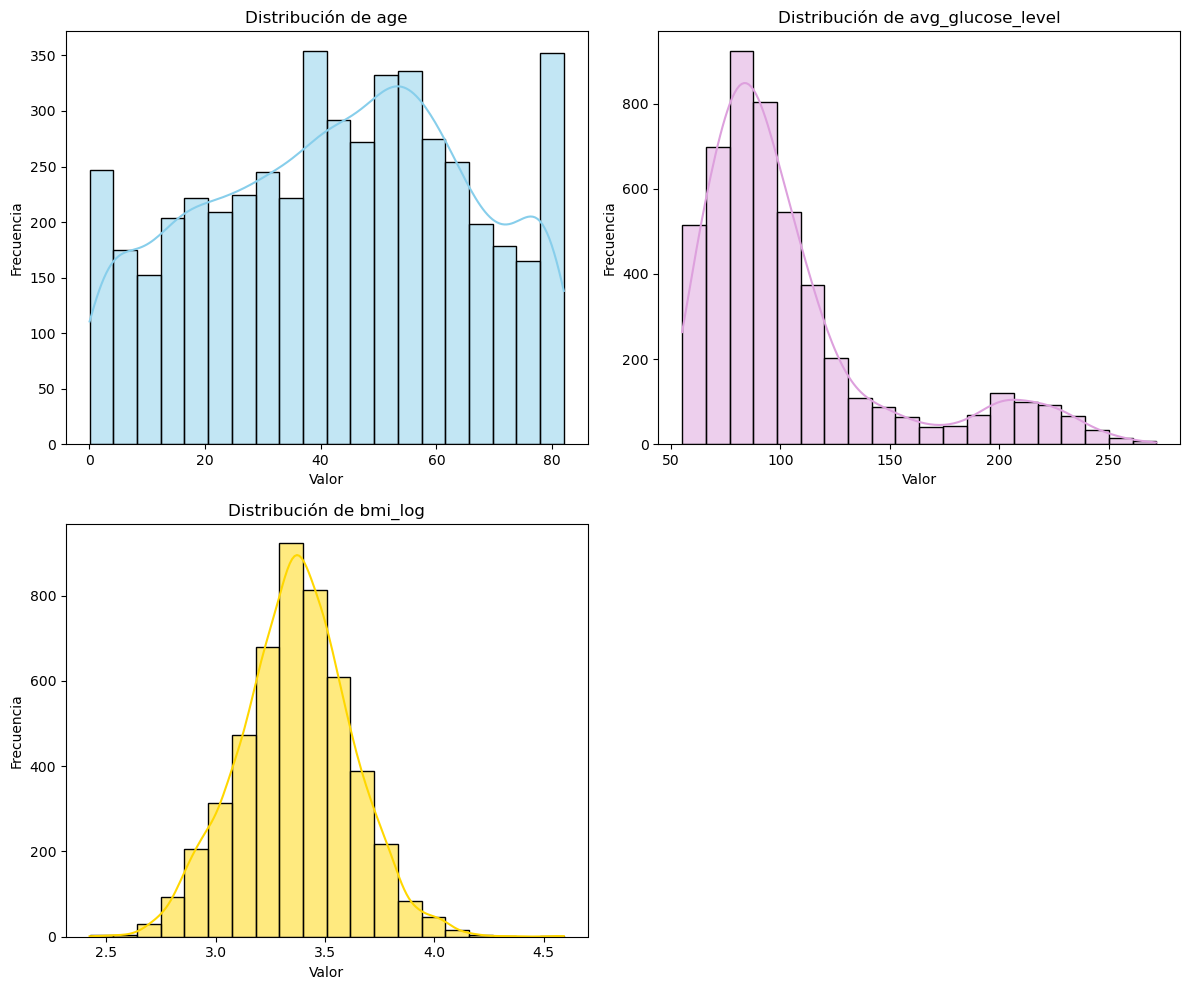

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

numeric_cols = ['age', 'avg_glucose_level', 'bmi_log']
colors = ['skyblue', 'plum', 'gold']
for idx, feature in enumerate(numeric_cols):
    ax = axes[idx // 2, idx % 2]

    # Histograma con KDE
    sns.histplot(data=df_encoded, x=feature, kde=True, bins=20, ax=ax, color=colors[idx])
    ax.set_title(f'Distribución de {feature}')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')

fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.savefig('./images/distribuciones_univariadas.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()

- Distribución 'age': Es una distribución bastante plana con una gran cantidad de ejemplos entre los 40 y 60 años. Lo más destacable es el pico final en los 80 años, que puede deberse al tope del dataset donde se han incluido a todos los mayores de 80 en la misma categoría.

- Distribución 'avg_glucose_level': Es una distribución asimétrica hacia la derecha donde se acumulan la gran mayoría de personas al principio en los valores normales de glucosa (sobre el 80). Lo que destaca es la cola hacia la derecha que va disminuyendo pero tiene un repunte cuando llega a 200, donde se establece un límite de gravedad en los pacientes y todos los que pertenezcan a ese rango en adelante tienen motivos por los que pudieran sufrir un ictus (son los outliers que no hemos eliminado en el tratamiento de los datos porque aportaban información clave en el estudio).

- Distribución 'bmi_log': Al haber realizado la tranformación logarítmica sobre la variable, hemos convertido la curva de la gráfica en una campana de Gauss (distribución normal) que de no haber aplicado seguiría siendo una cola larga hacia la derecha como es el caso de la glucosa. El pico lo obtenemos sobre el valor 3.3 y al ser normal tenemos una desviación mínima (se concentra todo).

### 2.3 Box Plots

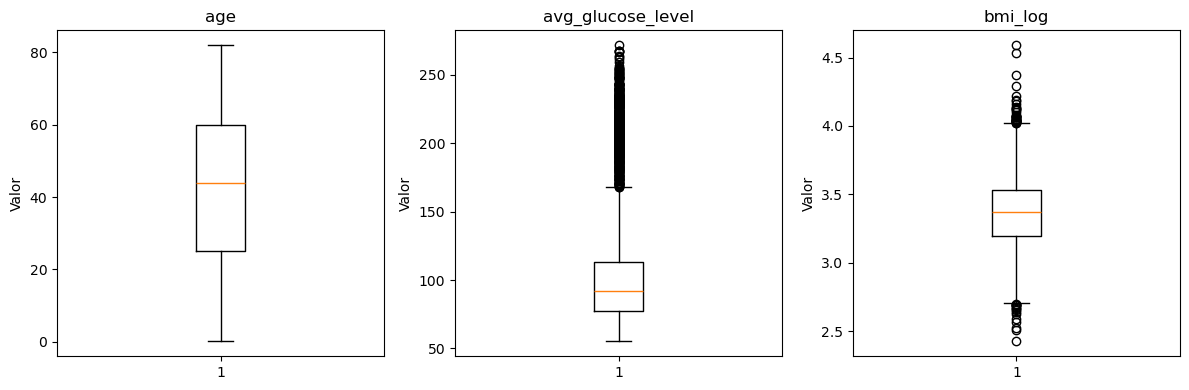

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for idx, feature in enumerate(numeric_cols):
    axes[idx].boxplot(df_encoded[feature])
    axes[idx].set_title(feature)
    axes[idx].set_ylabel('Valor')

plt.tight_layout()
plt.savefig('images/boxplots.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()

Como podemos ver en este análisis de los outliers, la variable 'age' (sin outliers) y la variable 'avg_glucose_level' (con muchos outliers) siguen igual que en el análisis hecho en el apartado 1. Sin embargo, en el gráfico correspondiente a la variable 'bmi_log', podemos observar como los outliers no se han eliminado sino que se han transformado. Al haber realizado la transformación logarítmica en el apartado 1, hemos conseguido centrar los valores del bmi y combinar los puntos tanto por encima como por debajo del rango normal para un bmi, mostrando una gráfica más ordenada y equilibrada.

### 2.4 Relaciones Bivariadas

                       age  avg_glucose_level   bmi_log
age                1.00000           0.236000  0.399370
avg_glucose_level  0.23600           1.000000  0.178794
bmi_log            0.39937           0.178794  1.000000


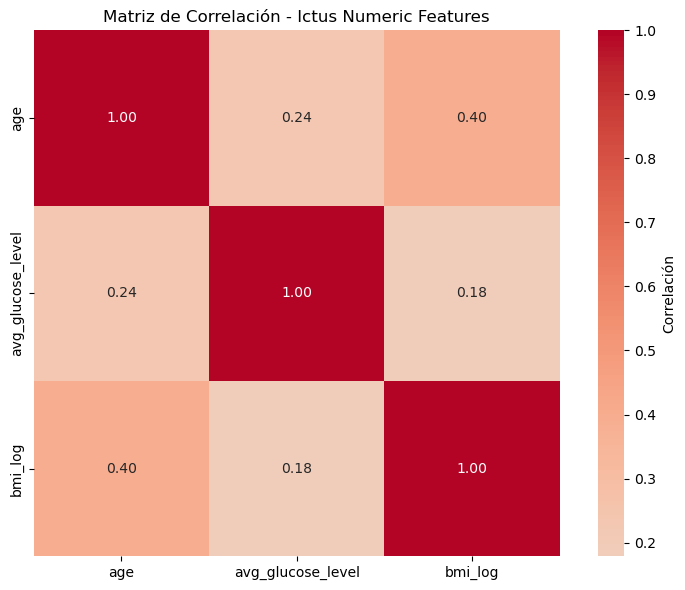

In [ ]:
# Matriz de correlación
corr_matrix = df_encoded[numeric_cols].corr()
print(corr_matrix)

# Visualización
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, ax=ax, cbar_kws={'label': 'Correlación'})
ax.set_title('Matriz de Correlación - Ictus Numeric Features')
plt.tight_layout()
plt.savefig('./images/correlacion_matrix.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()

En la matriz de correlación observamos que ninguna de las variables numéricas presenta una alta correlación entre sí. La relación más destacada se da entre \textit{age} y \textit{bmi_log} con un coeficiente de 0.40. Al igual que en las otras combinaciones, se trata de una correlación positiva pero débil.

Esta ausencia de correlaciones fuertes es muy positiva para el modelo predictivo, ya que descarta problemas de multicolinealidad. Desde un punto de vista médico aunque la edad, el peso y la glucosa están relacionados con la salud general, miden procesos fisiológicos independientes que no siempre aumentan de forma simultánea.

### 2.5 Scatter Plots

In [ ]:
colors = {0: 'lightgray', 1: 'red'}
labels = {0: 'Sanos (No Ictus)', 1: 'Pacientes con Ictus'}

def scatter_plots(vx, vy, correlacion):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))

    # Scatter simple: sepal_length vs petal_length
    axes[0].scatter(df_encoded[vx], df_encoded[vy], alpha=0.6)
    axes[0].set_xlabel(vx)
    axes[0].set_ylabel(vy)
    axes[0].set_title(f'Correlación: {correlacion}')
    axes[0].grid(True, alpha=0.3)

    # Scatter coloreado por species
    for estado in [0, 1]:
        mask = df_encoded['stroke'] == estado
        axes[1].scatter(df_encoded[mask][vx], df_encoded[mask][vy], color=colors[estado], label=labels[estado], alpha=0.7)
    axes[1].set_xlabel(vx)
    axes[1].set_ylabel(vy)
    axes[1].set_title('Estado de Ictus')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'./images/scatter_plots_{vx}-{vy}.png', dpi=400, bbox_inches='tight')
    plt.show()
    plt.close()

##### Edad - Nivel de glucosa

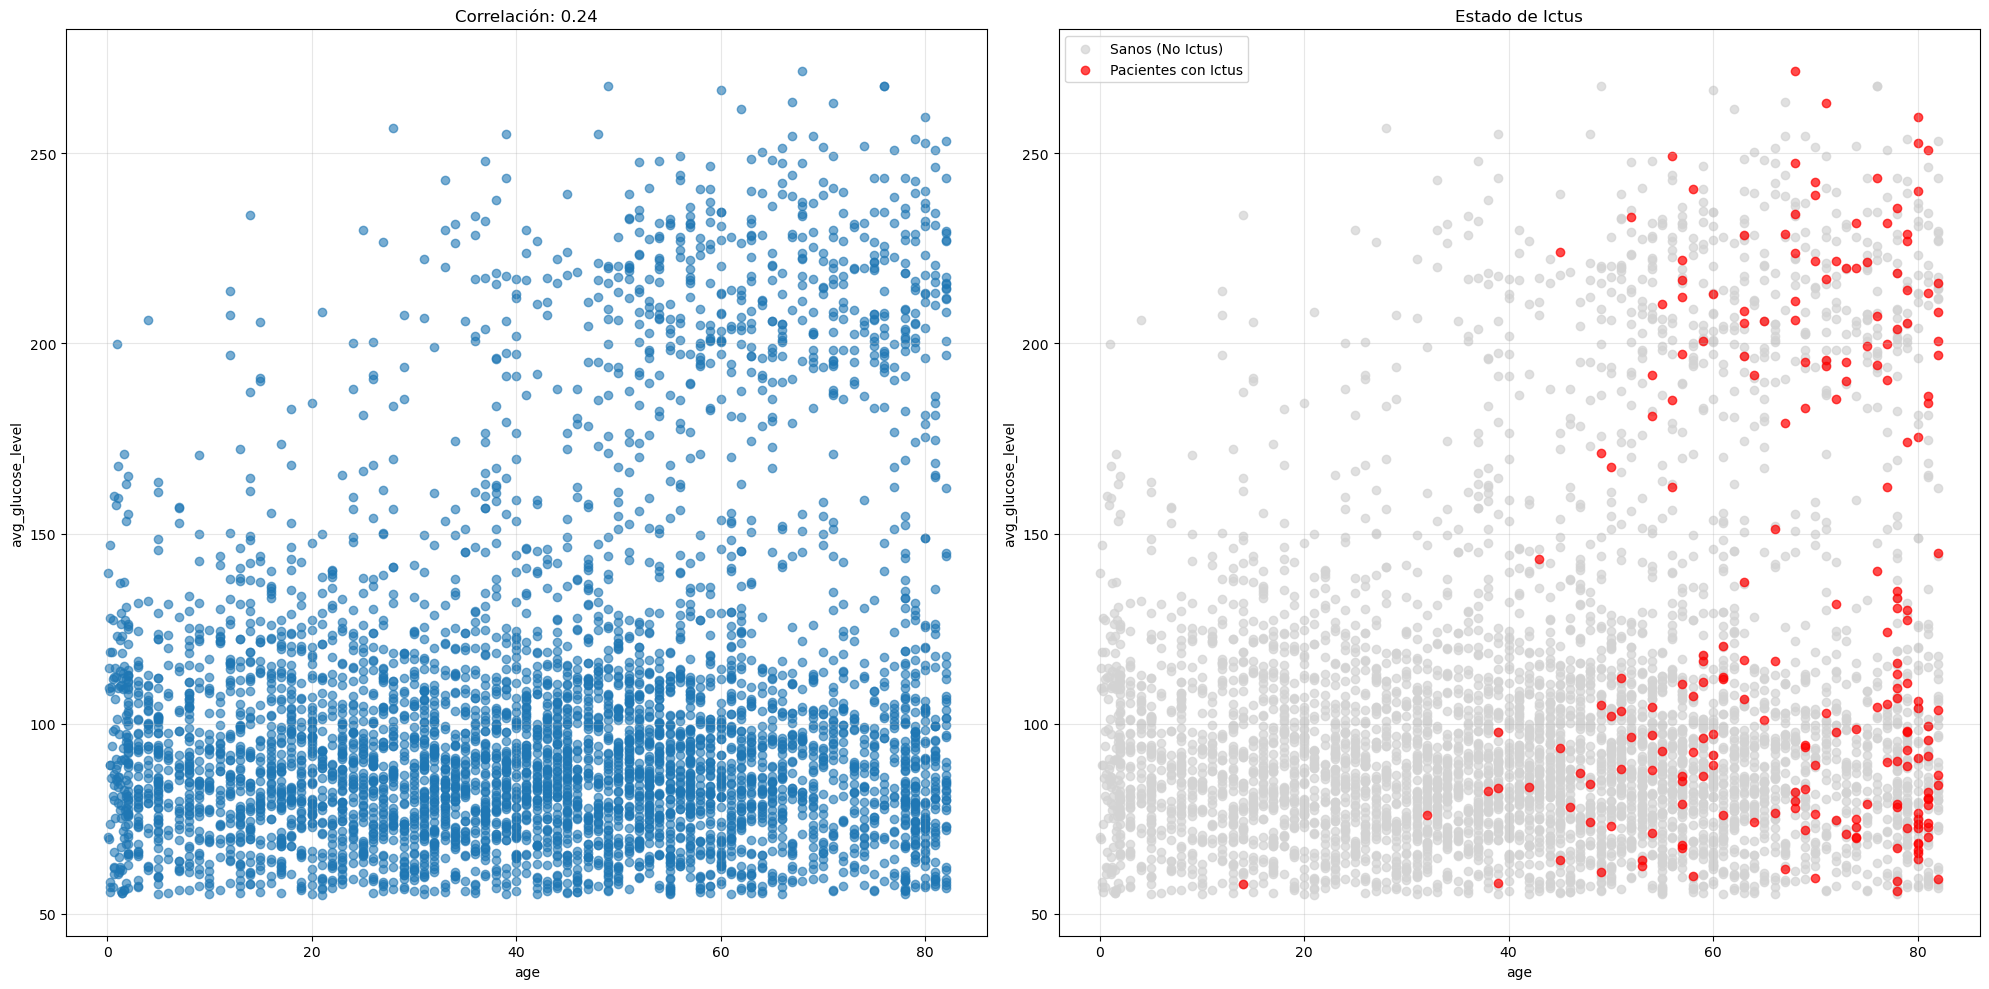

In [ ]:
scatter_plots('age', 'avg_glucose_level', 0.24)

##### Edad - BMI

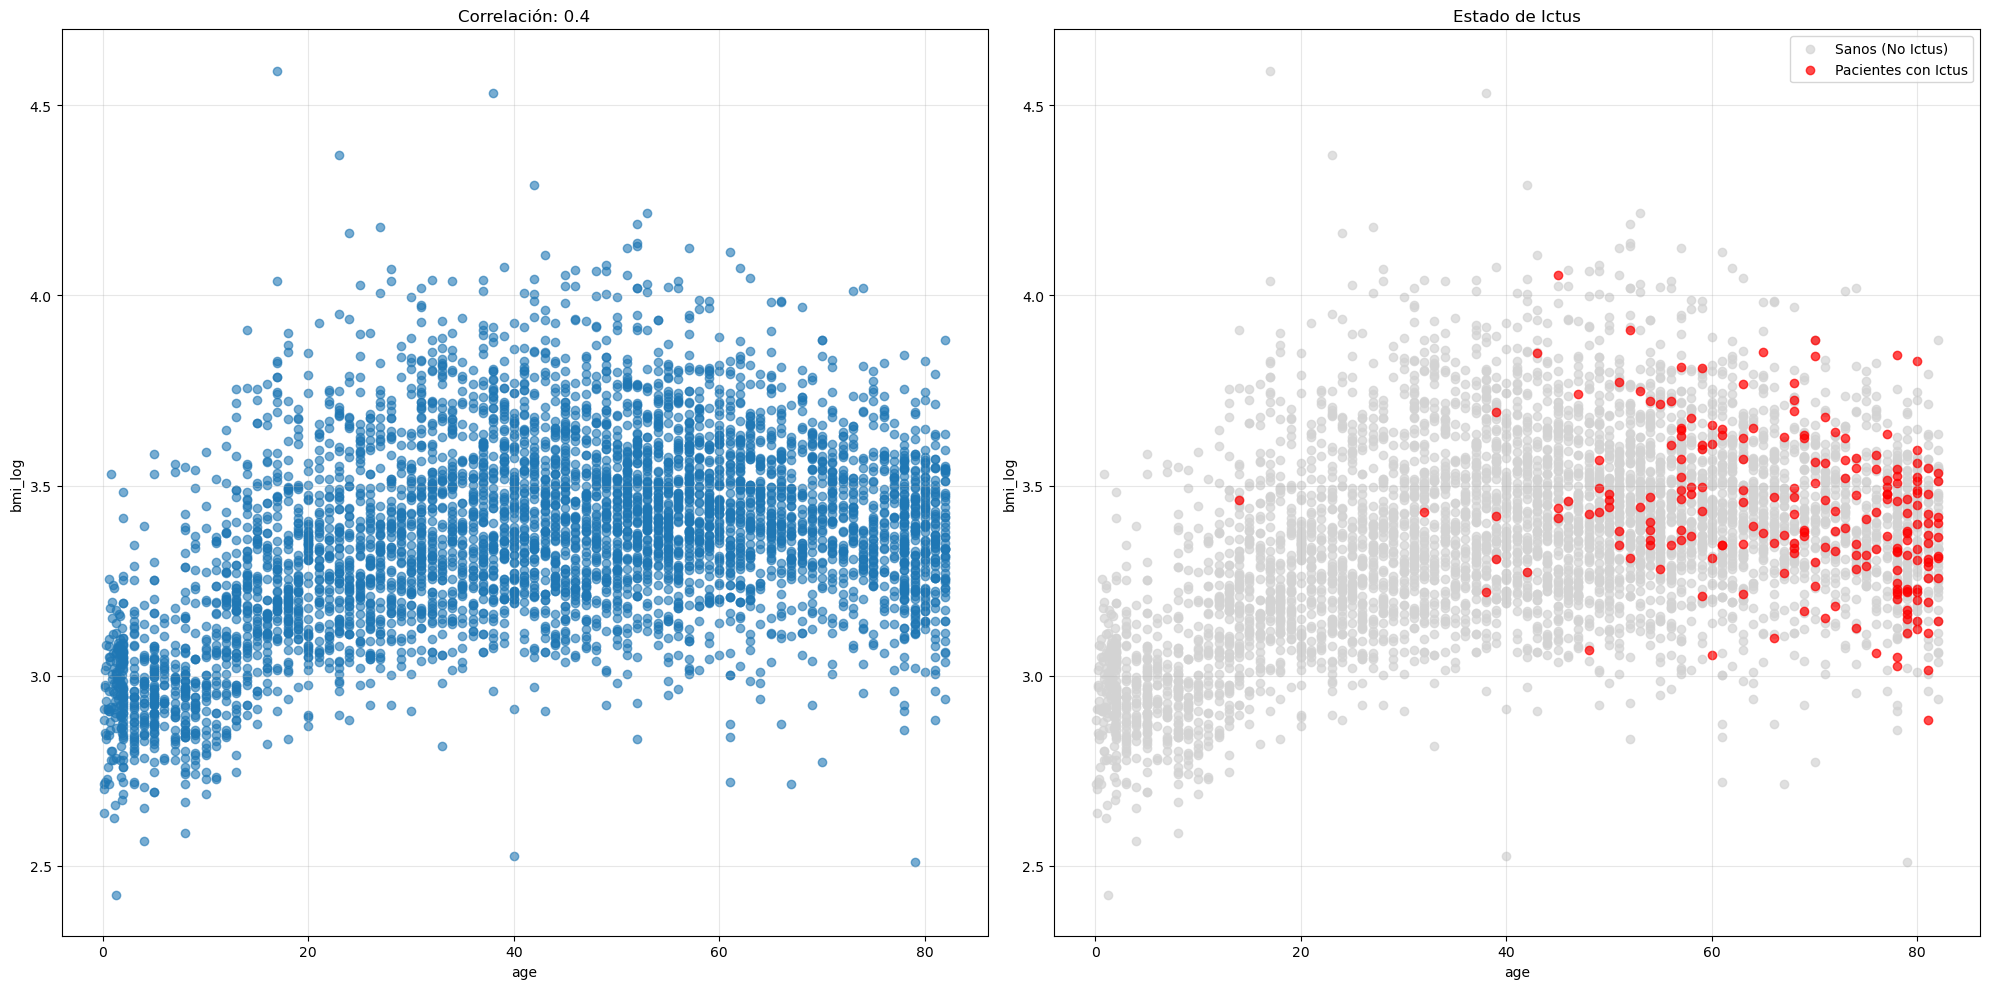

In [ ]:
scatter_plots('age', 'bmi_log', 0.4)

##### Nivel de glucosa - BMI

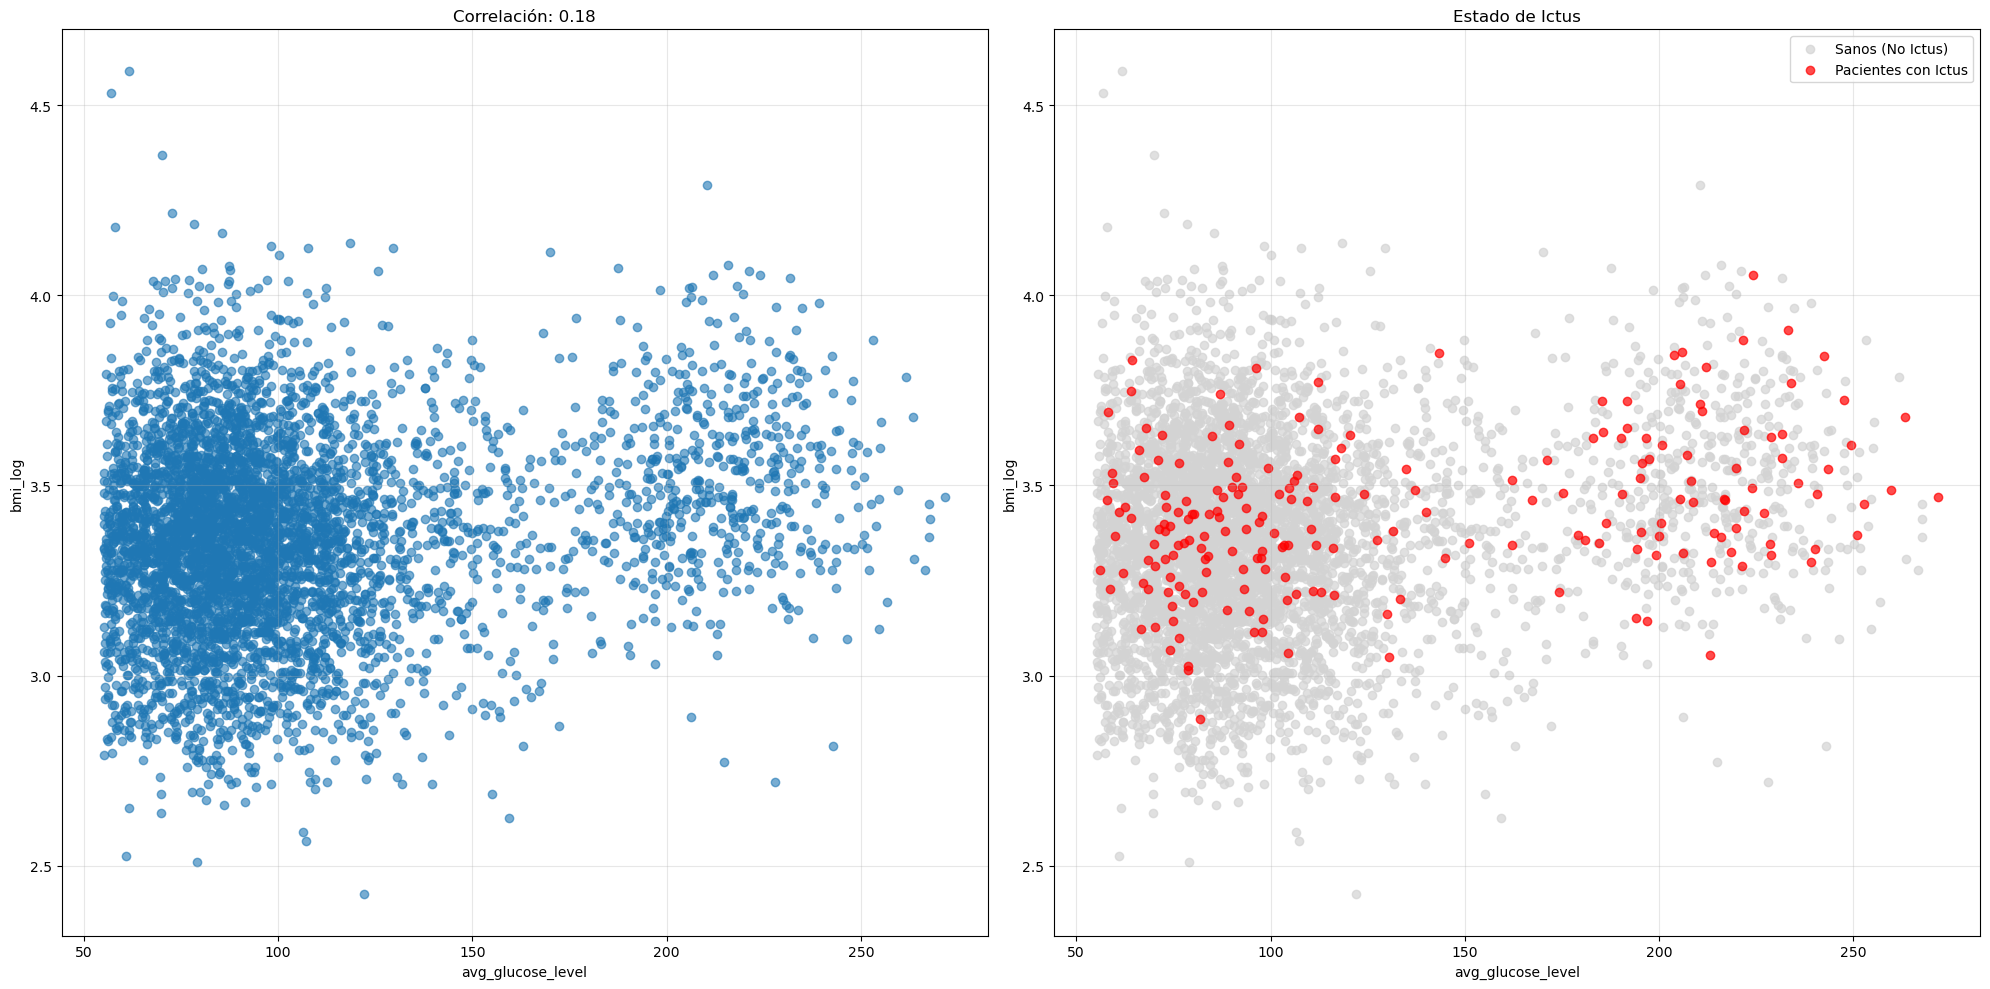

In [ ]:
scatter_plots('avg_glucose_level', 'bmi_log', 0.18)

Para las tres gráficas generadas, podemos observar claramente como los puntos rojos correspondientes a los pacientes con riesgo de ictus se infiltran entre las nubes grises de pacientes sanos, haciendo imposible la separación visual entre las clases.

### 2.6 Multicolinealidad

In [ ]:
# Mira correlaciones > 0.9
print(corr_matrix[corr_matrix > 0.9].sum())

age                  1.0
avg_glucose_level    1.0
bmi_log              1.0
dtype: float64


Al evaluar la matriz de correlación creada anteriormente, vemos que no hay ninguna combinación de características con una alta correlación (>0.9). Esto nos indica que no hay multicolinealidad, cada variable numérica aporta información única al modelo y los coeficientes son estables. Como resultado, no es necesario eliminar ninguna variable predictora ni reducir sus dimensionalidades, ya que podemos confiar en que los coeficientes que genere la regresión logística serán estables y directamente interpretables.

### 2.7 Imbalance y Representatividad

stroke
0    4699
1     209
Name: count, dtype: int64
4.2584% de personas sufren un ictus


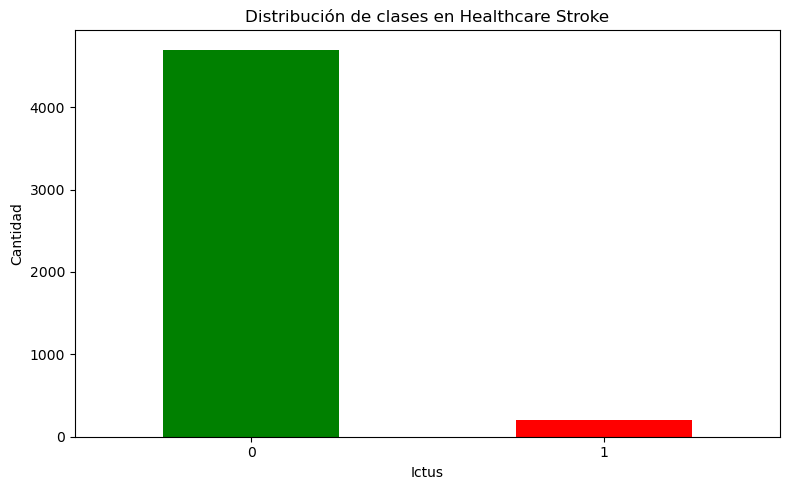

In [ ]:
# Conteo de clases
print(df_encoded['stroke'].value_counts())
ictus_no, ictus_yes = df_encoded['stroke'].value_counts()
porcentaje_ictus = (ictus_yes * 100) / (ictus_yes + ictus_no)
print(f'{round(porcentaje_ictus, 4)}% de personas sufren un ictus')

# Visualización
fig, ax = plt.subplots(figsize=(8, 5))
df_encoded['stroke'].value_counts().plot(kind='bar', ax=ax, color=['green', 'red'])
ax.set_title('Distribución de clases en Healthcare Stroke')
ax.set_xlabel('Ictus')
ax.set_ylabel('Cantidad')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig('./images/class_distribution.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()


Como podemos ver en esta gráfica, el dataset está extremadamente desbalanceado. Esto tiene una explicación lógica ya que la proporción de personas que sufren un ictus es muy pequeña en comparación a las que no, ya que no suele ser algo muy común. Al tener un dataset tan desbalanceado tendremos que tener cuidado con las métricas de accuracy con las que trabajaremos posteriormente, porque al tener la variable objetivo con un porcentaje tan bajo (4.2584%) podrán engañar con su resultado, ya que ante la duda lo más sencillo es responder que la persona analizada no ha sufrido ningún ictus.

### 2.8 Patrones, Anomalías e Insights

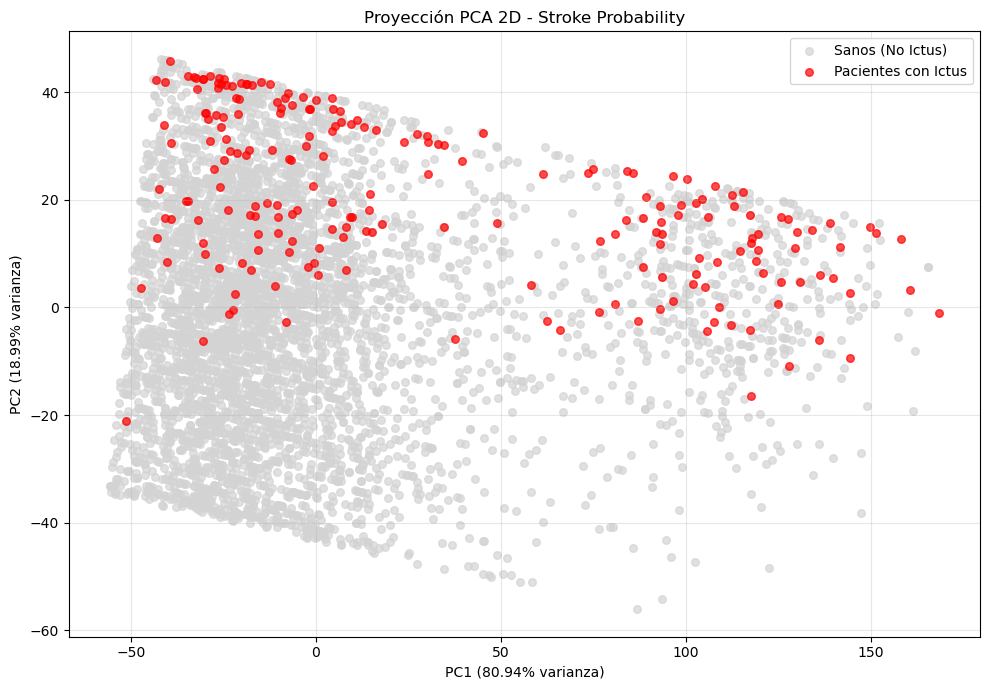

In [ ]:
# Conjunto de todas las columnas menos la variable objetivo
X_all = df_encoded.drop(columns=['stroke'])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all)

fig, ax = plt.subplots(figsize=(10, 7))

# Dibujo primero los sanos (0) y despúes los que han sufrido ictus (1)
for estado in [0, 1]:
    mask = df_encoded['stroke'] == estado
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=labels[estado], color=colors[estado], s=30, alpha=0.7)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} varianza)')
ax.set_title('Proyección PCA 2D - Stroke Probability')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./images/pca_visualization.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()

Con el análisis por PCA, hemos hecho el análisis completo a dos dimensiones que representan las dos direcciones de máxima varianza en el espacio multidimensional de los datos. 

Podemos observar como se concentra una gran nube de puntos grises en el centro del gráfico que representan a las personas que no han sufrido un ictus. Por otro lado, para los puntos rojos correspondientes a las personas que han sufrido un ictus detectamos dos agrupaciones separadas que pueden haber sido causa de la codificación de las variables categóricas, pero siguen estando presentes dentro de la nube gris de las personas sanas.

Esto nos dice que el sufrir un ictus no es un problema linealmente separable, ya que los pacientes que sufren un ictus comparten muchas características principales con pacientes sanos, lo que provoca el fuerte solapamiento en el espacio de componentes principales que hemos comentado anteriormente. También es relevante con la información de la varianza que nos da el gráfico, ya que al intentar resumir el cálculo en dos variables estamos perdiendo mucha información por el camino (varianzas de 80.94% y 18.99%).

## 3. Train-Test Split y Estandarización

### 3.1 Separación Train-Test

Para evitar que el modelo memorice, vamos a hacer una separación de los datos en dos subconjuntos, un 80% de los datos se irán a la partición destinada al entrenamiento y el 20% restante se irá destinado a la partición del test, buscando que en cada partición haya una proporción similar de datos de ambas clases objetivo.

In [ ]:
columns_list = df_encoded.drop(columns=['stroke']).columns.tolist()

# Split 80-20
X = df_encoded[columns_list].values
y = df_encoded['stroke'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# stratify=y asegura que cada split tenga proporción similar de clases
print(f"Train - Casos de Ictus (1): {sum(y_train == 1)} de {len(y_train)} ({sum(y_train == 1)/len(y_train):.2%})")
print(f"Test  - Casos de Ictus (1): {sum(y_test == 1)} de {len(y_test)} ({sum(y_test == 1)/len(y_test):.2%})")

Train: (3926, 15), Test: (982, 15)
Train - Casos de Ictus (1): 167 de 3926 (4.25%)
Test  - Casos de Ictus (1): 42 de 982 (4.28%)


### 3.2 Estandarización del Conjunto de Entrenamiento

Ya que no se ha hecho en el apartado 1.4 debido a que se debía hacer una partición de los datos, ahora es cuando realizo la estandarización.

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)  # FIT SOLO en train

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verificar
print(f"Train mean: {X_train_scaled.mean(axis=0)}")  # ~0
print(f"Train std: {X_train_scaled.std(axis=0)}")    # ~1
print(f"Test mean: {X_test_scaled.mean(axis=0)}")    # No es ~0 (datos nuevos)

Train mean: [-1.10004268e-16 -9.15241166e-16  5.97727562e-16  2.16615088e-16
  2.83070109e-17  4.26443281e-17 -2.53501867e-15 -1.10204764e-14
  4.50423646e-16 -1.43033827e-16  1.94897022e-16  1.21966172e-16
 -5.12354069e-16  4.58256855e-16 -8.85011202e-16]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Test mean: [ 0.06392843 -0.01341044 -0.0142071   0.03199622 -0.03769207  0.09114292
 -0.03300797  0.01075291  0.03193579 -0.03665599 -0.0417863   0.03639217
 -0.05789005 -0.02505248  0.00549368]


En los resultados obtenemos prácticamente 0 en las medias del conjunto de entrenamiento y una desviación estándar de 1. Por otro lado, para la partición del test las medias no son exactamente 0 (valores muy bajos pero que no se consideran 0), esto es debido a que el scaler ha sido ajustado solo con las estadísticas de la partición de entrenamiento, por lo que el subconjunto del test conserva su propia distribución al ser datos nuevos.

### 3.3 Modelo: Regresión Logística

Al tener un dataset tan desbalanceado, el modelo sabe por defecto que aproximadamente el 95% de los pacientes del dataset están sanos y no han sufrido un ictus, por lo que podría basarse en dar como negativo la mayoría de los casos y aún así seguiría teniendo un buen resultado. Esto lo que nos da son unos resultados falsos y que solo se basan en el porcentaje general de ictus en el conjunto completo de los datos, pero sin importarle si el diagnóstico de cada paciente está bien o no (el cual fallará prácticamente siempre). Es por ello que el uso del parámetro class_weight='balanced' dentro del modelo, obliga al algoritmo a predecir cada paciente por igual a pesar del rendimiento general equilibrando los pesos de cada uno. 

Para realizar la comprobación, he hecho una ejecución equilibrada y otra sin equlibrar:

##### Modelo sin equilibrar

In [ ]:
# Crear modelo
model_without_balance = LogisticRegression(
    max_iter=1000,
    random_state=42)

# Entrenar
model_without_balance.fit(X_train_scaled, y_train)

# Predicciones
y_pred_train_without_balance = model_without_balance.predict(X_train_scaled)
y_pred_test_without_balance = model_without_balance.predict(X_test_scaled)

# Probabilidades
y_proba_test_without_balance = model_without_balance.predict_proba(X_test_scaled)
print(y_proba_test_without_balance[:5])

[[9.99154609e-01 8.45391493e-04]
 [8.99376421e-01 1.00623579e-01]
 [9.72374761e-01 2.76252385e-02]
 [9.83512630e-01 1.64873704e-02]
 [9.73669938e-01 2.63300625e-02]]


##### Modelo equilibrado

In [ ]:
# Crear modelo
model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced' # Forzar que haga una predicción real y no se base en el desbalanceo del dataset
)

# Entrenar
model.fit(X_train_scaled, y_train)

# Predicciones
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

# Probabilidades
y_proba_test = model.predict_proba(X_test_scaled)
print(y_proba_test[:5])

[[0.98566544 0.01433456]
 [0.2860966  0.7139034 ]
 [0.61991612 0.38008388]
 [0.77200852 0.22799148]
 [0.707506   0.292494  ]]


Como podemos ver en los resultados de cada uno:

- En el modelo sin equilibrar, se dan prácticamente todos los casos a pacientes sanos con proporciones extremas como 0.999 ~ 0.001 de una clase a otra, significando que no se para a mirar cada paciente y su objetivo es dar un resultado final acorde al rendimiento global.
- En el modelo equilibrado, las proporciones cambian según el paciente y nos encontramos casos como 0.319 ~ 0.681 a favor de tener un ictus o 0.767 ~ 0.233 a favor de estar sano, lo que demuestra que el modelo hace una predicción real al ajustar el riesgo para cada uno de los pacientes teniendo en cuenta sus caratcterísticas.

Continuaremos con las predicciones hechas por el modelo equilibrado.

### 3.4 Métricas de Clasificación

#### Métricas principales

In [ ]:
# Accuracy: % correcto
acc = accuracy_score(y_test, y_pred_test)
print(f"Accuracy: {acc:.4f}")  # 1.0 (perfecto en este dataset)

# Precision (para clase i): TP / (TP + FP) - "de lo que predije positivo, cuánto fue correcto"
# Recall (para clase i): TP / (TP + FN) - "de los verdaderos positivos, cuántos encontré"
#
#  F1: Media armónica de Precision y Recall - "balance entre ambos"

print(classification_report(y_test, y_pred_test))

Accuracy: 0.7556


              precision    recall  f1-score   support

           0       0.98      0.76      0.86       940
           1       0.11      0.69      0.19        42

    accuracy                           0.76       982
   macro avg       0.55      0.72      0.53       982
weighted avg       0.94      0.76      0.83       982



Utilizando las predicciones del modelo balanceado obtenemos un accuracy del 0.7576. Con esta información y sabiendo que habíamos activado el parámetro de 'class_weight', tenemos un modelo sensible que está sobreestimando la cantidad de pacientes con riesgo de ictus, dando falsos positivos antes que falsos negativos. Esto en términos médicos podría ser clave, ya que se estaría primando el dar falsas alarmas a gente cercana a un posible ictus pero sin riesgo, que dejar pasar diagnósticos de pacientes que si que tengan un riesgo evidente y que el modelo no detecte, ya que en medicina, un falso positivo se puede descartar posteriormente al hacer pruebas al paciente, pero un falso positivo puede ser mortal.

En el resto de métricas, nos vamos a fijar más a fondo en el 'recall', que parte de la premisa que acabo de comentar. Hemos obtenido un recall del 71% para la clase de personas con riesgo de ictus, lo que quiere decir que es capaz de identificar correctamente a más de 7 de cada 10 pacientes en riesgo real. El contrario a este dato lo obtenemos en la métrica de 'precisión', donde para esta misma clase solo obtenemos un 12% que nos indica la gran tasa de falsos positivos que se han detectado.

Aunque esta sea la métrica que voy a utilizar, vamos a hacer la comprobación de como habrían salido los resultados si no hubiera balanceado el modelo antes de realizar las predicciones:

In [ ]:
acc_without_balance = accuracy_score(y_test, y_pred_test_without_balance)
print(f"Accuracy: {acc_without_balance:.4f}")

print(classification_report(y_test, y_pred_test_without_balance))

Accuracy: 0.9572
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       940
           1       0.00      0.00      0.00        42

    accuracy                           0.96       982
   macro avg       0.48      0.50      0.49       982
weighted avg       0.92      0.96      0.94       982



c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

Como podemos observar, el accuracy de la version desbalanceada ha sido de 0.9572, lo que nos indica que se ha hecho la predicción tal y como comentaba en el apartado de la regresión logística. Pese a que este accuracy sea tan elevado, no tiene ninguna fundamentación con las características del dataset, ya que ha predecido que nadie tiene riesgo de ictus en un dataset en el que casi nadie tiene riesgo de ictus, por lo que se esta mostrando un resultado falsamente elevado.

Analizando el resto de métricas, nos fijamos otra vez en el recall y la precisión. El recall para la clase 1 es de 0, por lo que de todos los pacientes que estaban sufriendo un ictus no ha detectado a ninguno y un 1 en la clase 0, diciendo que el 100% de los pacientes del dataset está sano. En la precisión también se ha dado un 0 para la clase 1, al no haber dado ninguna alarma de ictus y un 0.96 para la clase 0, debido a los pacientes graves que no se han detectado al igual que en el accuracy.

En resumen, en el campo de la medicina con el que estamos tratando en este dataset, es mejor ser más cautelosos a la hora de dar diagnósticos y así no fallar con los pacientes de riesgo, que son los verdaderamente importantes en el estudio.

##### Matriz de confusión

[[713 227]
 [ 13  29]]


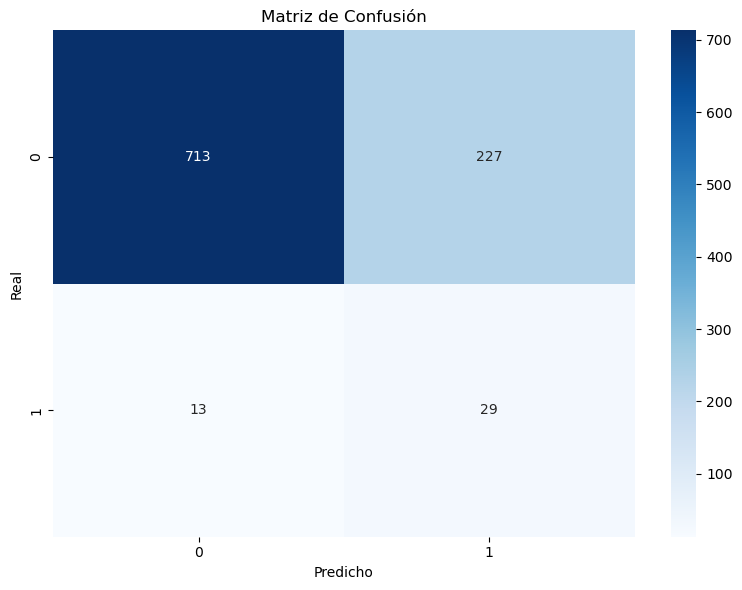

In [ ]:
cm = confusion_matrix(y_test, y_pred_test)
print(cm)

# Visualización
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=model.classes_, yticklabels=model.classes_)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión')
plt.tight_layout()
plt.savefig('./images/confusion_matrix.png', dpi=400, bbox_inches='tight')
plt.show()
plt.close()


Como podemos ver, esta matriz de confusión sobre el conjunto de test va en la línea de lo que he comentado anteriormente. En la diagonal principal podemos ver los pacientes que se han ajustado a su diagnóstico real y en la diagonal alternativa los errores de clasificación que ha tenido el modelo:

- Verdaderos negativos: 714 pacientes sanos que se han clasificado como sanos.
- Falsos positivos: 226 pacientes sanos que se han clasificado como pacientes de riesgo.
- Falsos negativos: 12 pacientes de riesgo que se han clasificado como sanos.
- Verdaderos positivos: 30 pacientes de riesgo que se han clasificado como pacientes de riesgo.

El número clave de esta matriz es el de los falsos negativos (12), ya que son los pacientes a los que se les da un diagnóstico falso que puede llevar a un ictus sin haber recibido tratamiento. Es el que corresponde a la precisión de la clase 1 en el cálculo de las métricas, por lo que si lo comparamos con el obtenido en la prueba del dataset desbalanceado, vemos que hemos reducido el falso diagnóstico en 30 pacientes graves (de 42 a 12).

### 3.5 Validación Cruzada

In [ ]:
# 5-fold cross-validation
cv_results = cross_validate(
    model,
    X_train_scaled, y_train,
    cv=5,
    scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
)

print(f"CV Accuracy: {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"CV F1: {cv_results['test_f1_weighted'].mean():.4f} ± {cv_results['test_f1_weighted'].std():.4f}")


CV Accuracy: 0.7583 ± 0.0206
CV F1: 0.8297 ± 0.0139


Al realizar la validación cruzada, estamos probando otros splits de train-test para comprobar que el resultado que teníamos era estable y consistente independientemente del subconjunto de datos seleccionado. El accuracy obtenido en el CV es prácticamente idéntico que el del apartado 3.4 (0.7567 ~ 0.7576), lo que nos indica que el modelo no ha memorizado y está generalizando bien (no hay overfitting). Con el resultado del F1 obtenemos el más alto hasta el momento (0.8287), la razón es que se le ha dado más peso a que los pacientes sean sanos. En cuanto a la desviación esándar, al ser tan baja (0.0214), sabemos que el modelo es muy estable.

## 4. Pipelines en Machine Learning

### 4.1 ¿Por qué Pipelines?

Para hacer encadenar múltiples transformaciones en un único objeto utilizamos un Pipeline, el cual es reproducible y reutilizable de manera automática, y que soluciona problemas como el data leakage y aporta métodos directos integrados como la validación cruzada o el grid search. Para hacer el pipeline vamos a reutilizar el dataset 'encoded' y volveremos a realizar la partición de los datos (porque en el apartado 3 los habíamos estandarizado) ya que tenemos que trabajar con datos limpios y nuevos. Esta partición será la que use para todos los ejemplos de pipeline a continuación, ya que cada pipeline realiza las transformaciones y operaciones en sí mismo, es decir, dentro del objeto.

In [ ]:
def split(version_dataset):
    columns_list = version_dataset.drop(columns=['stroke']).columns.tolist()

    # Split 80-20
    X = version_dataset[columns_list]
    y = version_dataset['stroke']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split(df_encoded)

### 4.2 Pipeline Básico

In [ ]:
# Crear pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# Entrenar
pipe.fit(X_train, y_train)

# Predecir
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)

# Evaluar
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy: {acc:.4f}")
print(f"F1: {f1:.4f}")


Accuracy: 0.7556
F1: 0.8277


Una ejecución base del pipeline nos hace la estandarización de los valores y ejecuta el modelo de regresión logística (adaptado con nuestro parámetro para balancear las clases). La creación del pipeline lo que nos ahorra es eso, todo el proceso del apartado 3 en un único objeto. Después de entrenarlo y realizar las predicciones, nos da un accuracy de 0.7556 y un F1 de 0.8277, mismos resultados que hemos obtenido calculando las métricas en el apartado 3, por lo que sabemos que realiza los mismos pasos.

### 4.3 ColumnTransformer

In [ ]:
# Transformer para numéricas
numeric_transformer = Pipeline([
    ('scaler', StandardScaler())
])

# Combinar transformers
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols)
])

# Pipeline completo
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# Usar igual que antes
full_pipeline.fit(X_train, y_train)
y_pred = full_pipeline.predict(X_test)

# Evaluar
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy: {acc:.4f}")
print(f"F1: {f1:.4f}")

Accuracy: 0.7240
F1: 0.8061


A diferencia del pipeline básico que aplica el mismo tratamiento a todo el dataset por igual, el ColumnTransformer nos permite crear apartados de preprocesamiento independientes según el tipo de dato. Este ejemplo de pipeline aísla únicamente las variables numéricas continuas para aplicarles el StandardScaler. El resto de variables (las categóricas que ya codificamos previamente con ceros y unos) pasarán directamente al modelo de Regresión Logística sin ser estandarizadas, por ello, nos salen unos resultados un poco inferiores.

### 4.4 Pipeline con GridSearchCV

Como modelo final y en el que vamos a basar nuestros resultados finales de la práctica, vamos a configurar un pipeline que se encargue de todo. Además de la estandarización y la regresión logística, introducimos un grid search que seleccionará los hiperparámetros que mejor rendimiento le den a nuestro modelo para obtener los resultados más altos posibles. Todo esto ejecutando también la cross validation y así asegurarnos que funciona para todo tipo de particiones de manera automática.

In [ ]:
pipe_grid = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])

# Parámetros a tunear
param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__max_iter': [1000, 2000]
}

# Grid search
grid = GridSearchCV(pipe_grid, param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Mejor C: {grid.best_params_['model__C']}")
print(f"Mejor max_iter: {grid.best_params_['model__max_iter']}")
print(f"Mejor score CV: {grid.best_score_:.4f}")

# Predecir con mejor modelo
y_pred = grid.predict(X_test)

Mejor C: 10
Mejor max_iter: 1000
Mejor score CV: 0.8298


Como resultados, obtenemos que la mejor ejecución la hemos consguido con un C=10 y max_iter=1000. Esto nos dice que los pacientes de ictus y los sanos están muy mezclados, por lo que necesita mucha flexibilidad para trazar la frontera entre una clase y otra (C=10), y que el modelo encontró la solución de forma eficiente y no ha tenido que ejecutarlo muchas veces para poder llegar al resultado óptimo (max_iter=1000). El resultado del F1-Score por parte de la cross validation usando estos hiperparámetros ha sido de 0.8298, que es el resultado más alto que hemos obtenido durante la práctica.

### Comparaciones con las versiones del dataset

In [ ]:
def pipeline_datasets(version_dataframe):

    # Separar variables
    X = version_dataframe.drop(columns=['stroke'], errors='ignore')
    y = version_dataframe['stroke']

    # Identificar columnas
    num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

    # Preprocesador (Solo escalar y codificar)
    preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
    ])

    # Pipeline
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(C=10, max_iter=1000, class_weight='balanced', random_state=42))
    ])

    # Entrenamiento y validación
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    # Mostrar resultados
    print(classification_report(y_test, y_pred))

##### healthcare-dataset-stroke-data (básico sin tocar)

Al realizar la regresión logística el código fallaría si encuentra algún valor vacío, por lo que los he tenido que eliminar antes de llamar al pipeline.

In [ ]:
df_temp1 = df.copy()
df_temp1 = df_temp1.dropna()
pipeline_datasets(df_temp1)

              precision    recall  f1-score   support

           0       0.98      0.76      0.85       940
           1       0.11      0.67      0.19        42

    accuracy                           0.75       982
   macro avg       0.55      0.71      0.52       982
weighted avg       0.94      0.75      0.83       982



##### 01_dataset_clean

In [ ]:
df_temp2 = df_clean.copy()
pipeline_datasets(df_temp2)

              precision    recall  f1-score   support

           0       0.98      0.76      0.86       940
           1       0.11      0.69      0.19        42

    accuracy                           0.75       982
   macro avg       0.55      0.72      0.52       982
weighted avg       0.94      0.75      0.83       982



##### 02_dataset_outliers

Son los mismos resultados que en mi modelo final. Esto se debe a que al tener que realizar la codificación si o si dentro del pipeline, la versión final del dataset y esta se quedarían prácticamente iguales.

In [ ]:
df_temp3 = df_outliers.copy()
pipeline_datasets(df_temp3)

              precision    recall  f1-score   support

           0       0.98      0.76      0.86       940
           1       0.11      0.69      0.19        42

    accuracy                           0.76       982
   macro avg       0.55      0.72      0.53       982
weighted avg       0.94      0.76      0.83       982

